# TD 1 : De la donnée brute à la donnée exploitable : nettoyage, modélisation et statistiques descriptives multimodales (CORRECTION)

> **À rendre :** un résumé de ce TD (2 pages maximum), à déposer dans votre dépôt GitLab.

## Objectif de la séance

Ce TD suit un **fil rouge unique** :

> **Donnée brute → donnée nettoyée → données décrites → features → sélection de variables → représentation du texte.**

À la fin du TD, vous devez être capables de :

1. auditer et nettoyer un jeu de données réel ;
2. identifier le type et le rôle des variables ;
3. construire un jeu de données exploitable par un modèle (`X` et `y`) ;
4. produire et interpréter des statistiques descriptives pour des variables numériques et catégorielles ;
5. créer de nouvelles variables par *feature engineering* ;
6. comparer plusieurs approches de *feature selection* ;
7. décrire une variable textuelle et comprendre comment la transformer en représentation numérique.

**Organisation pédagogique :**
- **Concept** : notion à retenir ;
- **Démo** : code guidé ;
- **À vous** : exercice à compléter.

Les sections 1 à 6 constituent ce TD. La suite (transformation du texte en TF-IDF, puis ouverture vers l'image et l'audio) se trouve dans `TD1_suite.ipynb`.

> **Version enseignant :** codes complétés et réponses aux questions.

## Jeux de données

| Modalité | Jeu de données | Utilisation |
|---|---|---|
| 🏠 Tabulaire | DVF : transactions immobilières à La Rochelle en 2024 | nettoyage, transformation, modélisation |
| 📝 Texte | Amazon Fine Food Reviews : échantillon de 10 000 avis | statistiques, feature engineering, texte |
| 🖼️ Image | `sklearn.datasets.load_digits` | représentation d'une image par des nombres |
| 🔊 Audio | Free Spoken Digit Dataset : échantillon de 60 fichiers | signal, durée, spectrogramme |

Le fichier DVF est utilisé au début parce qu'il ressemble à une **donnée brute issue d'un système réel**. Le jeu Amazon devient ensuite le **fil rouge principal** pour les statistiques, les features et le texte.

> Les chemins supposent que le dossier `data/` se trouve au même niveau que le notebook.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 100)

DATA = "../data"

print("Bibliothèques chargées.")
print("Dossier de données :", DATA)


Bibliothèques chargées.
Dossier de données : ../data


<a id="sec1"></a>
# 1. De la donnée brute à la donnée exploitable : nettoyage et transformation

### Concept

Avant toute analyse, il faut répondre à quatre questions :

1. **Quelle est la structure du fichier ?**
2. **Les lignes représentent-elles réellement les observations que je crois ?**
3. **Les types sont-ils corrects ?**
4. **Les valeurs et catégories sont-elles cohérentes ?**

Le nettoyage n'est donc pas seulement « supprimer les `NaN` ». Il consiste à comprendre la structure des données puis à appliquer les transformations nécessaires.


In [2]:
dvf = pd.read_csv(f"{DATA}/dvf_la_rochelle_2024.csv")

print("Dimensions :", dvf.shape)
dvf.head(5)


Dimensions : (3854, 14)


,id_mutation,date_mutation,nature_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,latitude
0,2024-176698,2024-01-03,Vente,126500.0,13.0,RUE ANDRE GABARET,17000.0,La Rochelle,Appartement,20.0,1.0,NaN,-1.159919,46.139451
1,2024-176702,2024-01-03,Vente,132300.0,13.0,RUE ANDRE GABARET,17000.0,La Rochelle,Appartement,20.0,1.0,NaN,-1.161599,46.139481
2,2024-176717,2024-01-09,Vente,235000.0,23.0,AV GENERAL LECLERC,17000.0,La Rochelle,Dépendance,NaN,0.0,NaN,-1.161177,46.162466
3,2024-176717,2024-01-09,Vente,235000.0,23.0,AV GENERAL LECLERC,17000.0,La Rochelle,Appartement,75.0,3.0,NaN,-1.161177,46.162466
4,2024-176727,2024-01-04,Vente en l'état futur d'achèvement,126120.0,NaN,RUE FLEMING,17000.0,La Rochelle,NaN,NaN,NaN,NaN,-1.157817,46.148331


### À vous : premier audit

Explorez les **colonnes** et les **lignes**. Identifiez au moins trois éléments qui méritent une vérification.

Utilisez notamment :

- `shape`
- `columns`
- `head()`
- `tail()`
- `info()`
- `describe(include="all")`

Regardez en particulier la transaction `2024-176717`.


In [3]:
# Objectif : repérer ce qui mérite une vérification dans le tableau DVF.

# Taille et types des colonnes (info() affiche aussi le nombre de cases remplies)
dvf.info()

# Part de cases vides par colonne, en pourcentage (isna() repère les cases vides)
print()
print((dvf.isna().mean() * 100).round(0).sort_values(ascending=False).head(5))

# La transaction citée dans l'énoncé
dvf[dvf["id_mutation"] == "2024-176717"]

<class 'pandas.DataFrame'>
RangeIndex: 3854 entries, 0 to 3853
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_mutation                3854 non-null   str    
 1   date_mutation              3854 non-null   str    
 2   nature_mutation            3854 non-null   str    
 3   valeur_fonciere            3853 non-null   float64
 4   adresse_numero             3307 non-null   float64
 5   adresse_nom_voie           3834 non-null   str    
 6   code_postal                3834 non-null   float64
 7   nom_commune                3854 non-null   str    
 8   type_local                 2919 non-null   str    
 9   surface_reelle_bati        1614 non-null   float64
 10  nombre_pieces_principales  2916 non-null   float64
 11  surface_terrain            1455 non-null   float64
 12  longitude                  3837 non-null   float64
 13  latitude                   3837 non-null   float64
dtypes: 

,id_mutation,date_mutation,nature_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,latitude
2,2024-176717,2024-01-09,Vente,235000.0,23.0,AV GENERAL LECLERC,17000.0,La Rochelle,Dépendance,NaN,0.0,NaN,-1.161177,46.162466
3,2024-176717,2024-01-09,Vente,235000.0,23.0,AV GENERAL LECLERC,17000.0,La Rochelle,Appartement,75.0,3.0,NaN,-1.161177,46.162466


### Réponse

Le tableau a **3 854 lignes** et **14 colonnes**. Voici quatre éléments à vérifier.

1. **Beaucoup de cases vides.** `surface_terrain` en a 62 %, `surface_reelle_bati` 58 % et `type_local` 24 %.
2. **Une ligne n'est pas une vente.** La transaction `2024-176717` occupe **2 lignes** : une dépendance et un appartement de 75 m².
3. **Le prix est répété.** Les 2 lignes affichent le même prix, 235 000 €. C'est le prix de la transaction entière, pas celui de chaque ligne. Si on additionne les prix des lignes, on compte la même vente deux fois.
4. **Des types étranges.** `code_postal` et `adresse_numero` sont lus comme des nombres décimaux (17000.0). Ce sont des codes, pas des quantités.

### Doublons et structure des observations

Dans DVF, plusieurs lignes peuvent correspondre à une même transaction (`id_mutation`) parce qu'une transaction peut concerner plusieurs lots ou composants.

Avant de supprimer des doublons, il faut donc comprendre ce que représente une ligne.


### À vous : doublons

1. Combien de lignes sont strictement identiques sur toutes les colonnes ?
2. Combien d’`id_mutation` apparaissent plusieurs fois dans le fichier ?
3. Combien d’`id_mutation` différents y a-t-il dans le fichier ?

Comparez les trois nombres et expliquez pourquoi ils sont différents.


In [4]:
# Objectif : comparer trois façons de compter les lignes de DVF.

# Lignes strictement identiques : duplicated() vaut True pour une ligne déjà vue plus haut (sur toutes les colonnes)
nb_doublons_stricts = dvf.duplicated().sum()
print("Doublons strictement identiques :", nb_doublons_stricts)

# Lignes dont l'id_mutation apparaît plusieurs fois : keep=False marque TOUTES les lignes du groupe, pas seulement les suivantes
nb_lignes_transactions_repetes = dvf["id_mutation"].duplicated(keep=False).sum()
print("Lignes avec id_mutation répété :", nb_lignes_transactions_repetes)

# Nombre de transactions différentes : nunique() compte les valeurs distinctes
nb_transactions = dvf["id_mutation"].nunique()
print("Id mutation distinctes :", nb_transactions)

# Bonus : combien d'id_mutation reviennent au moins deux fois ?
print("Id mutation qui reviennent :", (dvf["id_mutation"].value_counts() > 1).sum())

Doublons strictement identiques : 548
Lignes avec id_mutation répété : 3019
Id mutation distinctes : 1861
Id mutation qui reviennent : 1026


### Réponse

| Ce qu'on compte | Nombre |
|---|---:|
| lignes strictement identiques | 548 |
| lignes dont l'`id_mutation` apparaît plusieurs fois | 3 019 |
| `id_mutation` qui apparaissent plusieurs fois | 1 026 |
| `id_mutation` différents (donc transactions) | 1 861 |

**Pourquoi ces nombres sont différents.** Une ligne de DVF décrit **un lot** (un appartement, une cave, un garage), pas une vente entière. Une vente peut donc occuper plusieurs lignes : 3 854 lignes pour 1 861 transactions.

Les 548 lignes strictement identiques viennent de lots qui se ressemblent complètement. 88 % d'entre elles n'ont pas de surface bâtie renseignée, donc rien ne les distingue. Exemple : les deux premières dépendances de la transaction `2024-179588`.

**Faut-il les supprimer ?** Pas sans réfléchir. Ces lignes peuvent être de vrais lots différents. Avant de supprimer, il faut décider ce que représente une ligne dans l'analyse : un lot ou une vente.

### Transformer les catégories

Une variable catégorielle est une variable dont les valeurs représentent des catégories ou des groupes, plutôt que des quantités numériques.

Exemples :

- Sexe → Homme, Femme
- Ville → Paris, Lyon, Bordeaux
- Type de logement → Appartement, Maison
- Couleur → Rouge, Bleu, Vert
- Statut → Étudiant, Salarié, Retraité

On distingue généralement :

- **Catégorielle nominale** : pas d'ordre entre les catégories.
  → Ville = Paris, Lyon, Bordeaux
- **Catégorielle ordinale** : les catégories ont un ordre.
  → Satisfaction = Faible, Moyenne, Élevée



Les variables catégorielles sont souvent stockées sous forme de texte (`Maison`, `Appartement`, etc.). Un modèle statistique ou de machine learning travaille généralement avec une représentation numérique.

Le **One-Hot Encoding** est une méthode qui permet de transformer une variable catégorielle en plusieurs variables numériques binaires (0 ou 1).

Le **one-hot encoding** transforme par exemple :

| type_local | → | Appartement | Maison | Dépendance |
|---|---:|---:|---:|---:|
| Appartement | | 1 | 0 | 0 |
| Maison | | 0 | 1 | 0 |

Attention : encoder une catégorie ne signifie pas lui attribuer arbitrairement un ordre.


In [5]:
# Démo : distribution de type_local
dvf["type_local"].value_counts(dropna=False)


type_local
Dépendance                                  1301
Appartement                                  939
NaN                                          935
Maison                                       491
Local industriel. commercial ou assimilé     188
Name: count, dtype: int64

In [6]:
# Démo : one-hot encoding
type_local_encode = pd.get_dummies(
    dvf["type_local"].fillna("Non renseigne"),
    prefix="type_local",
    dtype=int
)
type_local_encode.head().style.hide(axis="index")


type_local_Appartement,type_local_Dépendance,type_local_Local industriel. commercial ou assimilé,type_local_Maison,type_local_Non renseigne
1,0,0,0,0
1,0,0,0,0
0,1,0,0,0
1,0,0,0,0
0,0,0,0,1


### À vous : transformer une autre variable

Encodez `nature_mutation` avec `pd.get_dummies()` puis vérifiez que les colonnes obtenues correspondent bien aux modalités observées avec `value_counts()`.

**Question :** pourquoi faut-il traiter explicitement les valeurs manquantes avant ou pendant l'encodage ?


In [7]:
# Objectif : transformer nature_mutation en colonnes de 0 et de 1 (one-hot encoding).

# fillna remplace une case vide par un texte explicite. Ici il n'y en a aucune, mais cela protège si le fichier change.
nature_mutation_encode = pd.get_dummies(
    dvf["nature_mutation"].fillna("Non renseigne"),
    prefix="nature_mutation",
    dtype=int
)

# Vérification : le nombre de 1 de chaque colonne doit être égal à l'effectif de chaque modalité
print(nature_mutation_encode.sum())
print()
print(dvf["nature_mutation"].value_counts())

nature_mutation_encode.head()

nature_mutation_Adjudication                             4
nature_mutation_Echange                                 16
nature_mutation_Vente                                 3439
nature_mutation_Vente en l'état futur d'achèvement     393
nature_mutation_Vente terrain à bâtir                    2
dtype: int64

nature_mutation
Vente                                 3439
Vente en l'état futur d'achèvement     393
Echange                                 16
Adjudication                             4
Vente terrain à bâtir                    2
Name: count, dtype: int64


,nature_mutation_Adjudication,nature_mutation_Echange,nature_mutation_Vente,nature_mutation_Vente en l'état futur d'achèvement,nature_mutation_Vente terrain à bâtir
0,0,0,1,0,0
1,0,0,1,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,0,1,0


### Réponse

On obtient **5 colonnes**, une par modalité de `nature_mutation`. Le nombre de `1` de chaque colonne est égal à l'effectif donné par `value_counts()` (par exemple 3 439 pour `Vente`). L'encodage est donc correct.

**Pourquoi traiter les valeurs manquantes ?** Sans cela, une ligne sans valeur reçoit des `0` dans toutes les colonnes. On ne peut plus distinguer « ce n'est pas une vente » de « on ne sait pas ». Avec `fillna("Non renseigne")`, on garde une colonne qui dit clairement « inconnu ».

Pour `type_local`, cela concerne 935 lignes. Ici, `nature_mutation` n'a aucune case vide.

### Créer une première feature

Une donnée exploitable n'est pas forcément une donnée brute. On peut construire une variable plus informative à partir de plusieurs colonnes.

Pour les logements, le **prix au m²** est plus comparable que le prix total :

`prix_m2 = valeur_fonciere / surface_reelle_bati`

Mais une feature calculée n'est jamais meilleure que les données dont elle dépend : une surface erronée produit un prix au m² erroné.


In [8]:
batis = dvf[dvf["type_local"].isin(["Maison", "Appartement"])].copy()
batis["prix_m2"] = batis["valeur_fonciere"] / batis["surface_reelle_bati"]

batis["prix_m2"].describe()


count     1429.000000
mean      5743.835802
std       5068.265852
min          0.018519
25%       3674.698795
50%       4800.000000
75%       5974.025974
max      68452.375000
Name: prix_m2, dtype: float64

### Question d'interprétation

Observez le minimum et le maximum de `prix_m2`.

- Voyez-vous des valeurs surprenantes ?
- Faut-il immédiatement les supprimer ?
- Quelle information faudrait-il vérifier avant de décider ?

**À retenir :** une anomalie doit d'abord être **diagnostiquée**, pas automatiquement supprimée.


### Réponse

Le minimum est de **0,02 €/m²** (1 € pour 54 m²). Le maximum est de **68 452 €/m²** (2 190 476 € pour 32 m²). Ces deux valeurs sont très surprenantes. Il y a 5 biens sous 100 €/m² et 33 biens au-dessus de 20 000 €/m².

**Faut-il les supprimer tout de suite ?** Non. Le maximum vient de la transaction `2024-179588`, qui a **7 lignes** : deux appartements, quatre dépendances et un lot sans type. Le prix de 2 190 476 € paie **tous** les lots. Mais on le divise par la surface d'**un seul** appartement (32 m²). Le calcul est faux, pas la donnée.

**Que vérifier avant de décider ?** Combien de lignes compte la transaction, et si le prix est celui de la transaction entière ou celui d'un lot. Un prix de 1 € est peut-être symbolique (une cession, par exemple) : il ne reflète pas la valeur du bien. Il faut regarder la transaction avant de conclure.

<a id="sec2"></a>

# 2. Modéliser les données : préparer les variables

### Qu'est-ce que « modéliser les données » ?

**Modéliser les données**, ici, signifie simplement **préparer et représenter les données dans une forme adaptée à l'analyse que l'on souhaite réaliser**.

Les données brutes ne sont pas toujours directement utilisables. On peut par exemple :

* sélectionner les variables utiles ;
* traiter les valeurs manquantes ;
* transformer certaines variables ;
* transformer les catégories en nombres lorsque cela est nécessaire (le one-hot encoding, vu en section 1).

### Et `X` et `y` ?

Lorsque l'on souhaite faire une prédiction, on distingue généralement :

* **`y`** : ce que l'on cherche à prédire ;
* **`X`** : les variables utilisées pour faire cette prédiction.

Par exemple, si l'on cherche à prédire la **valeur foncière** :

```text
X = surface, nombre de pièces, type_local, ...
y = valeur foncière
```

Pour le moment, retenons simplement :

> **`X` = les informations que l'on utilise**
> **`y` = l'information que l'on cherche à prédire**

In [9]:
df = pd.read_csv(f"{DATA}/amazon_reviews_sample.csv")

print("Dimensions :", df.shape)
df.head(3)


Dimensions : (10002, 6)


,ProductId,Helpfulness,Score,Time,Summary,Text
0,B000EVG8J2,0/0,5.0,1268179200,Crunchy & Good Gluten-Free Sandwich Cookies!,"Having tried a couple of other brands of gluten-free sandwich cookies, these are the best of the..."
1,B0000BXJIS,0/0,5.0,1298937600,great kitty treats,"My cat loves these treats. If ever I can't find her in the house, I just pop the top and she bol..."
2,B008FHUFAU,0/2,3.0,1224028800,COFFEE TASTE,A little less than I expected. It tends to have a muddy taste - not what I expected since they ...


In [10]:
# Types techniques détectés par pandas
df.dtypes


ProductId          str
Helpfulness        str
Score          float64
Time             int64
Summary            str
Text               str
dtype: object

### À vous : reconnaître les types de variables

Dans cette partie, **on cherche à comprendre quelles informations contient chaque colonne et à déterminer quelles colonnes peuvent être utiles pour analyser les avis**.

Observez les différentes colonnes du jeu de données et indiquez **quel type d'information** contient chacune d'elles.

| Colonne       | Type de variable |
| ------------- | ---------------- |
| `ProductId`   | ???              |
| `Score`       | ???              |
| `Time`        | ???              |
| `Helpfulness` | ???              |
| `Text`        | ???              |

**Aide** : les principaux types de variables

* **Numérique** : contient une quantité ou une mesure.
  *Exemple :* prix, surface, âge, nombre de pièces.

* **Catégorielle** : contient des catégories ou des groupes.
  *Exemple :* maison/appartement, ville, couleur.

* **Temporelle** : contient une date ou un moment dans le temps.
  *Exemple :* date d'achat, année, heure.

* **Textuelle** : contient du texte libre.
  *Exemple :* commentaire, description, avis.

* **Identifiant** : sert principalement à identifier une observation ou un objet.
  *Exemple :* numéro de produit, numéro de client.

> **Attention :** le type affiché par Python ne correspond pas toujours au type statistique de la variable. Une colonne peut contenir des nombres sans représenter une quantité. Par exemple, `ProductId` peut être numérique dans Python, mais il s'agit avant tout d'un **identifiant**.

### Questions

1. Quel est le type de chaque colonne ?
2. Quelles colonnes peuvent apporter des **informations utiles pour analyser les avis** ?
3. Quelle colonne ressemble davantage à un **identifiant** qu'à une véritable caractéristique du produit ou de l'avis ?
4. `Time` peut-être enregistré sous la forme d'un nombre. Pourquoi ce nombre représente-t-il malgré tout une **information temporelle** ?



### Réponse

| Colonne | Type de variable | Pourquoi |
|---|---|---|
| `ProductId` | **Identifiant** | C'est le code d'un produit. Il ne mesure rien. |
| `Score` | **Numérique** (note de 1 à 5) | On peut aussi la voir comme une catégorie ordonnée : 5 est mieux que 4. |
| `Time` | **Temporelle** | C'est un moment, écrit comme un nombre de secondes. |
| `Helpfulness` | **Texte à découper** | `0/2` veut dire : 0 personne a trouvé l'avis utile, sur 2 votes. Il faut séparer les deux nombres. |
| `Text` | **Textuelle** | C'est le contenu de l'avis. |

**Question 2 : colonnes utiles pour analyser les avis.** `Score` (l'opinion), `Text` (ce que dit le client), `Time` (l'évolution dans le temps) et `Helpfulness` (après l'avoir séparée en deux nombres).

**Question 3 : l'identifiant.** `ProductId`. Il sert à reconnaître un produit, il ne décrit ni le produit ni l'avis.

**Question 4 : pourquoi `Time` est une information temporelle.** Ce nombre compte les secondes écoulées depuis le 1er janvier 1970. Il est ordonné (un nombre plus grand veut dire plus tard) et on peut le convertir en date. Par exemple, `1268179200` correspond au 10/03/2010.

<a id="sec3"></a>

# 3. Statistiques descriptives : variables numériques et catégorielles

Avant de faire des prédictions, il est important de **comprendre les données que l'on possède**.

Les **statistiques descriptives** permettent de résumer les données avec quelques indicateurs et quelques graphiques.

## 3.1 Décrire une variable numérique

Une variable numérique contient des **nombres qui représentent une quantité** : un prix, une surface, un âge, un nombre de pièces, une note, etc.

Pour la décrire, on peut chercher plusieurs informations :

* **Tendance centrale** : indique où se situent généralement les valeurs.

  * **Moyenne** : somme des valeurs divisée par leur nombre.
  * **Médiane** : valeur qui partage les données en deux groupes de même taille.

* **Dispersion** : indique si les valeurs sont proches ou éloignées les unes des autres.

  * **Écart-type** : mesure à quel point les valeurs s'éloignent de la moyenne.
  * **Étendue** : différence entre la plus grande et la plus petite valeur.
  * **Variance** : autre mesure de la dispersion des valeurs.

* **Position** : permet de situer une valeur par rapport aux autres.

  * **Quantiles** : partagent les données en plusieurs groupes de même taille. Par exemple, le premier quartile indique la valeur en dessous de laquelle se trouvent 25 % des observations.

* **Forme de la distribution** : permet de voir comment les valeurs sont réparties.

  * **Histogramme** : montre la répartition des valeurs.
  * **Boxplot** : permet notamment de visualiser la médiane, la dispersion et les valeurs atypiques.
  * **Asymétrie** : indique si la distribution est équilibrée ou si elle est davantage étirée d'un côté.

## 3.2 Décrire une variable catégorielle

Une variable catégorielle contient des **catégories ou des groupes**, par exemple le type de logement (`Maison`, `Appartement`), une ville ou un type de produit.

Pour la décrire, on peut compter **combien d'observations appartiennent à chaque catégorie** :

* **Effectif** : nombre d'observations dans une catégorie.
* **Fréquence** : nombre d'observations rapporté à l'ensemble des observations.
* **Proportion** : part que représente une catégorie dans l'ensemble des données, souvent exprimée en pourcentage.
* **Modalité rare** : catégorie qui apparaît très peu souvent dans les données.

Par exemple, si un jeu de données contient 1 000 logements et que 600 sont des appartements, alors l'effectif des appartements est **600** et leur proportion est **60 %**.

> **À retenir :** les statistiques descriptives permettent donc de répondre à des questions simples :
> **Quelles sont les valeurs typiques ? Les données sont-elles dispersées ? Quelles catégories sont les plus fréquentes ? Y a-t-il des valeurs inhabituelles ?**



In [11]:
print("Score, statistiques descriptives")
print("Moyenne :", round(df["Score"].mean(), 3))
print("Médiane :", df["Score"].median())
print("Écart-type :", round(df["Score"].std(), 3))

df["Score"].describe()


Score, statistiques descriptives
Moyenne : 4.196
Médiane : 5.0
Écart-type : 1.296


count    10002.000000
mean         4.196061
std          1.296489
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: Score, dtype: float64

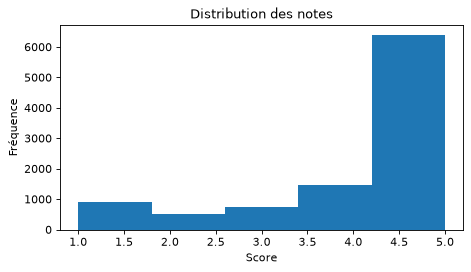

In [12]:
# Distribution de Score
df["Score"].plot(kind="hist", bins=5, figsize=(6, 3.5))
plt.title("Distribution des notes")
plt.xlabel("Score")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()


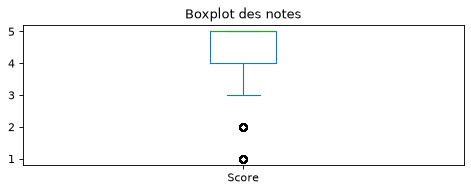

In [13]:
# Boxplot
df["Score"].plot(kind="box", figsize=(6, 2.5))
plt.title("Boxplot des notes")
plt.tight_layout()
plt.show()


### À vous : interpréter plutôt que calculer

1. La moyenne et la médiane sont-elles proches ?
2. La distribution paraît-elle équilibrée ?
3. Que vous apprend le boxplot ?
4. Quelle note est majoritaire ?

Calculez ensuite les fréquences et pourcentages de chaque note.


In [14]:
# Objectif : compter les avis de chaque note, en nombre et en pourcentage.

# value_counts() compte les avis par note ; sort_index() range les notes de 1 à 5
frequences_score = df["Score"].value_counts().sort_index()

# normalize=True donne des proportions entre 0 et 1 ; on multiplie par 100 pour avoir des pourcentages
pourcentages_score = (df["Score"].value_counts(normalize=True).sort_index() * 100).round(1)

print("Fréquences :")
print(frequences_score)

print("\nPourcentages :")
print(pourcentages_score)

Fréquences :
Score
1.0     891
2.0     507
3.0     750
4.0    1456
5.0    6398
Name: count, dtype: int64

Pourcentages :
Score
1.0     8.9
2.0     5.1
3.0     7.5
4.0    14.6
5.0    64.0
Name: proportion, dtype: float64


### Réponse

1. **La moyenne et la médiane sont-elles proches ?** Non. La moyenne est de 4,20 et la médiane de 5. La médiane est plus haute que la moyenne.
2. **La distribution est-elle équilibrée ?** Non. Presque toutes les notes sont hautes. La courbe est étirée vers les petites notes.
3. **Que montre le boxplot ?** La boîte va de 4 à 5 : la moitié des avis est entre 4 et 5. La médiane est collée au bord haut. Les notes 1 et 2 apparaissent comme des points isolés : ce sont des **valeurs atypiques**.
4. **Quelle note est majoritaire ?** La note **5**, avec 6 398 avis, soit 64,0 %.

| Note | Avis | Pourcentage |
|---:|---:|---:|
| 1 | 891 | 8,9 % |
| 2 | 507 | 5,1 % |
| 3 | 750 | 7,5 % |
| 4 | 1 456 | 14,6 % |
| 5 | 6 398 | 64,0 % |

**Pourquoi la moyenne est plus basse que la médiane ?** Les quelques avis à 1 ou 2 étoiles tirent la moyenne vers le bas. La médiane, elle, ne bouge presque pas.

### Décrire une variable numérique construite

Nous allons maintenant créer `TextLength`, puis appliquer exactement le même raisonnement :

> **construire → décrire → visualiser → interpréter**


Moyenne : 434.0
Médiane : 299.0
Écart-type : 432.0


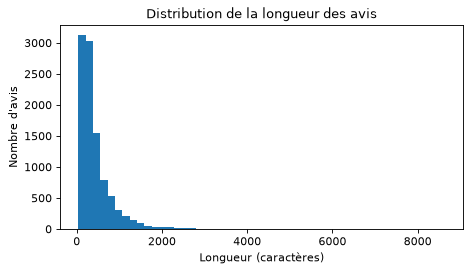

In [15]:
# Objectif : mesurer la longueur de chaque avis (en caractères) et la décrire comme une variable numérique.

# str.len() compte les caractères de chaque texte
df["TextLength"] = df["Text"].str.len()

print("Moyenne :", round(df["TextLength"].mean(), 1))
print("Médiane :", df["TextLength"].median())
print("Écart-type :", round(df["TextLength"].std(), 1))

# Histogramme : bins=50 découpe l'axe en 50 barres
df["TextLength"].plot(kind="hist", bins=50, figsize=(6, 3.5))
plt.title("Distribution de la longueur des avis")
plt.xlabel("Longueur (caractères)")
plt.ylabel("Nombre d'avis")
plt.tight_layout()
plt.show()

### Réponse

La moyenne est de 434,0 caractères, la médiane de 299 et l'écart-type de 432,0.

**Lecture.** La moyenne est bien plus haute que la médiane, et l'écart-type est presque aussi grand que la moyenne. L'histogramme montre beaucoup d'avis courts et quelques avis très longs : la distribution est **étirée vers la droite**. Quelques longs avis suffisent à tirer la moyenne vers le haut.

Pour décrire la longueur d'un avis typique, on préférera donc la **médiane**.

### Relation entre deux variables

Lorsque l'on étudie deux variables numériques, on peut se demander si **elles évoluent ensemble**.

Par exemple, on peut chercher à savoir si une augmentation de la **surface d'un logement** est associée à une augmentation de son **prix**.

La **corrélation** est un indicateur qui permet de mesurer la **force et le sens d'une relation entre deux variables**.

* Une corrélation **positive** signifie que les deux variables ont tendance à augmenter ensemble.
* Une corrélation **négative** signifie que lorsque l'une augmente, l'autre a tendance à diminuer.
* Une corrélation **proche de zéro** signifie qu'on ne détecte pas de relation linéaire claire entre les deux variables.

### Deux mesures courantes de corrélation `Pearson` et `Spearman`


### Pearson : mesurer une relation linéaire

La **corrélation de Pearson** permet de mesurer si deux variables numériques ont tendance à **évoluer ensemble de manière linéaire**.

Par exemple, imaginons quelques logements :

| Surface (m²) | Prix (€) |
| -----------: | -------: |
|           40 |  120 000 |
|           50 |  150 000 |
|           60 |  180 000 |
|           70 |  210 000 |
|           80 |  240 000 |

On observe ici que **plus la surface augmente, plus le prix augmente**.

La corrélation de Pearson sera alors **proche de +1**, ce qui indique une **forte relation linéaire positive**.

À l'inverse :

* une corrélation proche de **+1** → les deux variables augmentent ensemble ;
* une corrélation proche de **-1** → quand une variable augmente, l'autre diminue ;
* une corrélation proche de **0** → pas de relation linéaire claire.

>Pearson mesure une **association**, et non une relation de cause à effet. Une forte corrélation ne signifie donc pas nécessairement qu'une variable **cause** l'autre.


### Spearman : comparer les rangs

La **corrélation de Spearman** cherche à savoir si, lorsque les valeurs d'une variable augmentent, les valeurs de l'autre variable ont tendance à **augmenter ou diminuer elles aussi**.

Elle ne regarde pas directement les valeurs, mais plutôt **leur classement (leur rang)**.

Par exemple, imaginons que l'on compare le **nombre d'heures d'étude** et la **note obtenue** :

| Étudiant | Heures d'étude | Note |
| -------- | -------------: | ---: |
| A        |              1 |    8 |
| B        |              2 |   10 |
| C        |              4 |   13 |
| D        |              7 |   15 |
| E        |             10 |   16 |

Même si la progression des notes n'est pas parfaitement régulière, on constate que :

**plus le nombre d'heures d'étude augmente, plus la note a tendance à augmenter.**

Les rangs suivent donc globalement le même ordre :

```text
Heures d'étude :  1 → 2 → 4 → 7 → 10
Note           :  8 → 10 → 13 → 15 → 16
```

La corrélation de **Spearman** sera alors **positive et élevée**.

### Pearson ou Spearman ?

* **Pearson** → cherche surtout une relation **linéaire** entre les valeurs.
* **Spearman** → regarde surtout si les **rangs évoluent dans le même sens**.

> **À retenir :** Pearson s'intéresse davantage aux **valeurs**, tandis que Spearman s'intéresse davantage à leur **ordre**.


In [16]:
# 
from scipy.stats import pearsonr, spearmanr

pearson_r, _ = pearsonr(df["Score"], df["TextLength"])
spearman_r, _ = spearmanr(df["Score"], df["TextLength"])

print("Pearson  :", round(pearson_r, 3))
print("Spearman :", round(spearman_r, 3))


Pearson  : -0.067
Spearman : -0.114


### À vous: comparaison de groupes

Comparez la longueur moyenne des avis notés **5** et **1**.

Cette comparaison confirme-t-elle, nuance-t-elle ou contredit-elle votre interprétation de la corrélation ?


In [17]:
# Objectif : comparer la longueur moyenne des avis à 5 étoiles et des avis à 1 étoile.

# df["Score"] == 5 garde seulement les avis à 5 étoiles ; on prend ensuite leur longueur moyenne
moyenne_5 = round(df[df["Score"] == 5]["TextLength"].mean(), 1)
moyenne_1 = round(df[df["Score"] == 1]["TextLength"].mean(), 1)

print("Longueur moyenne (5 étoiles) :", moyenne_5)
print("Longueur moyenne (1 étoile)  :", moyenne_1)

Longueur moyenne (5 étoiles) : 406.1
Longueur moyenne (1 étoile)  : 473.0


### Réponse

Les avis à 1 étoile sont plus longs que les avis à 5 étoiles : 473,0 contre 406,1 caractères, soit 16 % de plus.

**Cette comparaison confirme le sens de la corrélation, mais elle la nuance.**

* Elle **confirme** : les corrélations sont négatives (Pearson -0,067, Spearman -0,114). Plus la note est basse, plus l'avis tend à être long.
* Elle **nuance** : les corrélations sont proches de 0. Le lien est donc **faible**. L'écart de 67 caractères est petit devant l'écart-type (432 caractères).

On peut le comprendre : quelqu'un de déçu explique ce qui ne va pas, alors que quelqu'un de content écrit souvent quelques mots. Mais la longueur seule ne permet pas de deviner la note.

<a id="sec4"></a>
# 4. De la donnée brute à la donnée modèle : feature engineering

### Concept

Le **feature engineering** consiste à créer des variables qui représentent mieux le phénomène étudié.

Exemples :

- une date → année, mois, jour de la semaine ;
- un texte → longueur, nombre de mots, vocabulaire ;
- deux variables → ratio ou différence ;
- plusieurs observations → nombre d'événements antérieurs.

L'objectif n'est pas de créer « le plus de variables possible », mais des variables **pertinentes, interprétables et disponibles au moment de la prédiction**.


In [18]:
# Transformer le timestamp en variables temporelles
df["Time"] = pd.to_datetime(df["Time"], unit="s")

df["annee"] = df["Time"].dt.year
df["mois"] = df["Time"].dt.month
df["jour_semaine"] = df["Time"].dt.dayofweek
df["est_weekend"] = df["jour_semaine"] >= 5

df[["Time", "annee", "mois", "jour_semaine", "est_weekend"]].head()


,Time,annee,mois,jour_semaine,est_weekend
0,2010-03-10,2010,3,2,False
1,2011-03-01,2011,3,1,False
2,2008-10-15,2008,10,2,False
3,2012-04-25,2012,4,2,False
4,2012-04-18,2012,4,2,False


### À vous : utiliser l'historique des avis

Un même produit peut recevoir plusieurs avis au cours du temps.

Pour chaque avis, nous voulons créer une nouvelle variable appelée **`nb_avis_avant`**.

Cette variable indique **combien d'avis sur le même produit ont été publiés avant la date de cet avis**.

Par exemple :

| ProductId | Date de l'avis | `nb_avis_avant` |
| --------- | -------------- | --------------: |
| A         | 1 janvier      |               0 |
| A         | 5 janvier      |               1 |
| A         | 10 janvier     |               2 |
| A         | 20 janvier     |               3 |
| B         | 3 janvier      |               0 |
| B         | 15 janvier     |               1 |

### À vous de jouer

Construisez la variable **`nb_avis_avant`** à partir de `ProductId` et `Time`.

**Indice :**

* Commencez par trier les avis par produit et par date.
* Puis cherchez une fonction permettant de **compter les avis précédents pour chaque produit**.

### Question

`nb_avis_avant` peut-il apporter **plus d'information** que `ProductId` seul ?




In [19]:
# Objectif : pour chaque avis, compter les avis déjà publiés sur le même produit.

# Étape 1 : trier par produit puis par date
df = df.sort_values(["ProductId", "Time"]).reset_index(drop=True)

# Étape 2 : groupby range les avis par produit ; cumcount() numérote les avis de chaque produit en partant de 0.
#           Le premier avis d'un produit a donc 0 avis avant lui, le deuxième 1, etc.
df["nb_avis_avant"] = df.groupby("ProductId").cumcount()

df[["ProductId", "Time", "nb_avis_avant"]].head(10)

,ProductId,Time,nb_avis_avant
0,7310172001,2010-07-05,0
1,7310172001,2011-04-27,1
2,7310172001,2012-06-22,2
3,7310172101,2007-07-20,0
4,7310172101,2009-03-10,1
5,7310172101,2010-03-22,2
6,7310172101,2011-06-03,3
7,7310172101,2012-09-10,4
8,B00004CI84,2008-10-08,0
9,B00004CI84,2008-11-28,1


### Réponse

Le premier avis du produit `7310172001` a `0` avis avant lui, le deuxième `1`, le troisième `2`. Quand on passe au produit suivant, le compteur repart de `0`.

**`nb_avis_avant` apporte-t-il plus d'information que `ProductId` seul ?** Oui.

* `ProductId` est un identifiant : il dit **quel** produit, pas **où en est** le produit. Un modèle ne peut rien en tirer pour un produit nouveau.
* `nb_avis_avant` est un nombre qui change au cours du temps. Il indique si le produit est récent ou déjà très commenté. Il existe aussi pour un produit jamais vu.

**Attention, un détail.** 59 avis ont le même produit et la même date. Leur ordre est alors arbitraire, donc leur `nb_avis_avant` aussi. Pour être strict, il faudrait compter seulement les avis **plus anciens**.

### Éviter les fuites d'information

Une feature est valide si elle est **disponible au moment où la prédiction est faite**.

Par exemple, `nb_avis_avant` est construit avec les avis précédents. En revanche, utiliser le nombre **total d'avis du produit**, calculé avec tout le dataset, peut utiliser indirectement des informations futures.

> **Feature engineering = créer de l'information utile sans regarder le futur.**


<a id="sec5"></a>

# 5. Sélection de variables : quelles variables conserver ?

Après avoir créé plusieurs variables, nous pouvons avoir **plusieurs features**.

Toutes les variables ne sont pas forcément utiles. Nous allons donc chercher à identifier celles qui semblent apporter le plus d'information.

Il existe plusieurs familles de méthodes :

* **Méthode filtre** : utilise un critère statistique pour évaluer les variables.
* **Méthode wrapper** : teste différents ensembles de variables avec un modèle.
* **Méthode embarquée** : le modèle participe directement à la sélection.

Nous allons comparer les trois, sur le même jeu de données (Iris).

## 5.1 Méthode filtre

La méthode filtre consiste à **évaluer les variables avant d'utiliser un modèle**.

Pour chaque variable, nous calculons un score permettant de mesurer son lien avec la variable `y`.

Dans notre exemple, nous allons utiliser le **score ANOVA F**.

L'idée est simple :

* **score F élevé** → la variable présente des différences importantes entre les groupes de `y` ;
* **score F faible** → les valeurs sont plus proches entre les groupes.

Le score permet donc de **classer les variables** selon leur intérêt.


### Exemple

Supposons que `y` indique l'**espèce d'une fleur** (le dataset Iris).

Nous disposons de plusieurs variables numériques :

| Variable             | Information         |
| --------------------- | -------------------- |
| `sepal length (cm)`  | longueur du sépale   |
| `sepal width (cm)`   | largeur du sépale    |
| `petal length (cm)`  | longueur du pétale   |
| `petal width (cm)`   | largeur du pétale    |

Nous voulons savoir quelles variables présentent les différences les plus importantes entre les trois espèces.

L'ANOVA F va donner **un score à chaque variable**.

In [20]:
from sklearn.datasets import load_iris

iris = load_iris()

In [21]:
import pandas as pd

df_iris = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df_iris["target"] = iris.target

df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dans notre exemple :

* `X` contient les mesures des fleurs ;
* `y` indique l'espèce de la fleur.

Nous allons utiliser ANOVA F pour déterminer quelles variables de `X` sont les plus intéressantes pour distinguer les catégories de `y`.


In [22]:
X = df_iris.drop(columns="target")

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [23]:
y = df_iris["target"]

y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [24]:
# Observer les catégories de y
# On découvre qu'il existe 3 groupes.
y.value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [25]:
# Importer ANOVA F
from sklearn.feature_selection import SelectKBest, f_classif

In [26]:
# Créer le sélecteur
selecteur = SelectKBest(
    score_func=f_classif, #indique que nous utilisons ANOVA F.
    k="all"
)

In [27]:
# Calculer les scores
selecteur.fit(X, y)

SelectKBest(k='all')

In [28]:
#  Associer les scores aux noms
scores_filtre = pd.Series(
    selecteur.scores_,
    index=X.columns
)

scores_filtre

sepal length (cm)     119.264502
sepal width (cm)       49.160040
petal length (cm)    1180.161182
petal width (cm)      960.007147
dtype: float64

In [29]:
# Classer les variables
scores_filtre = scores_filtre.sort_values(
    ascending=False
)

scores_filtre

petal length (cm)    1180.161182
petal width (cm)      960.007147
sepal length (cm)     119.264502
sepal width (cm)       49.160040
dtype: float64

### À vous : interpréter les scores

Observez le résultat obtenu.

1. Quelle variable possède le score ANOVA F le plus élevé ?
2. Quelle variable possède le score le plus faible ?
3. Quelles sont les deux variables qui semblent les plus intéressantes pour distinguer les espèces de fleurs ?

**Rappel :**

> Plus le score ANOVA F est élevé, plus les valeurs de la variable sont différentes entre les groupes de `y`.


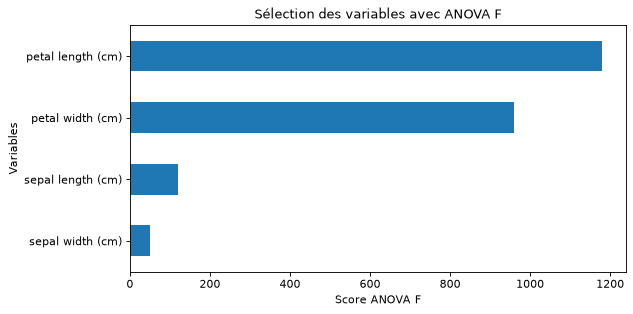

In [30]:
import matplotlib.pyplot as plt

scores_filtre.sort_values().plot(
    kind="barh",
    figsize=(8, 4)
)

plt.xlabel("Score ANOVA F")
plt.ylabel("Variables")
plt.title("Sélection des variables avec ANOVA F")
plt.show()

### Réponse

| Variable | Score ANOVA F |
|---|---:|
| `petal length (cm)` | 1 180,2 |
| `petal width (cm)` | 960,0 |
| `sepal length (cm)` | 119,3 |
| `sepal width (cm)` | 49,2 |

1. **Score le plus élevé :** `petal length (cm)`, la longueur du pétale (1 180,2).
2. **Score le plus faible :** `sepal width (cm)`, la largeur du sépale (49,2).
3. **Les deux variables les plus intéressantes :** la longueur et la largeur du **pétale**. Leurs scores sont bien plus grands que ceux des sépales : les trois espèces se distinguent surtout par la taille du pétale.

In [31]:
# Je souhaite conserver les 2 variables ayant les meilleurs scores ANOVA F.
selecteur_2 = SelectKBest(
    score_func=f_classif,
    k=2
)

X_selection = selecteur_2.fit_transform(X, y)

X_selection.shape

(150, 2)

In [32]:
variables_selectionnees = X.columns[
    selecteur_2.get_support()
]

variables_selectionnees

Index(['petal length (cm)', 'petal width (cm)'], dtype='str')

In [33]:
# Créer le nouveau X
X_reduit = X[variables_selectionnees]

X_reduit.head()

,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


### À retenir

Nous avons suivi les étapes suivantes :

**1. Préparer les données**

```text
X → variables numériques
y → catégories à comparer
```

**2. Calculer un score ANOVA F**

Chaque variable reçoit un score.

**3. Classer les variables**

Les scores les plus élevés apparaissent en premier.

**4. Visualiser les résultats**

Un graphique permet de comparer facilement les variables.

**5. Sélectionner les meilleures variables**

Nous pouvons finalement conserver les variables ayant les meilleurs scores.

> **Méthode filtre :**
>
> **variables → score statistique → classement → sélection**


## 5.2 Méthode wrapper

La méthode wrapper consiste à **tester différents sous-ensembles de variables avec un modèle**, et à garder celui qui donne les meilleurs résultats.

**RFE, ce n'est pas un modèle.** C'est une technique qui utilise un modèle existant (ici une régression logistique) pour décider, étape par étape, quelle variable retirer. RFE répète ceci :

1. entraîner le modèle avec les variables actuellement en jeu (au tout début, c'est-à-dire toutes les variables) ;
2. regarder quelle variable a le moins pesé dans sa décision ;
3. retirer cette variable ;
4. recommencer, jusqu'à ce qu'il ne reste que le nombre de variables demandé.

Contrairement à la méthode filtre, elle prend en compte les **interactions entre les variables**, mais elle est plus coûteuse en calcul puisqu'elle réentraîne le modèle plusieurs fois.

In [34]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

modele = LogisticRegression(max_iter=200)
rfe = RFE(modele, n_features_to_select=2)
rfe.fit(X, y)

variables_wrapper = X.columns[rfe.support_]
variables_wrapper

Index(['petal length (cm)', 'petal width (cm)'], dtype='str')

**À vous.** Comparez les variables gardées par RFE à celles qui avaient le meilleur score ANOVA F en 5.1. Sont-elles les mêmes ?

### Réponse

**Oui, ce sont les mêmes** : RFE garde `petal length (cm)` et `petal width (cm)`, qui sont aussi les deux meilleurs scores ANOVA F.

La différence apparaît sur les deux variables écartées. Pour l'ANOVA F, la longueur du sépale (119,3) passe avant sa largeur (49,2). Pour RFE, c'est l'inverse : la largeur est retirée en dernier (rang 2), la longueur est retirée en premier (rang 3). Le filtre regarde chaque variable seule. RFE regarde les variables ensemble, donc il peut juger autrement.

## 5.3 Méthode embarquée

La méthode embarquée laisse le **modèle participer directement à la sélection**, pendant son propre entraînement : pas besoin d'étape séparée, le modèle indique lui-même quelles variables il a utilisées.

Un exemple classique : le Random Forest (forêt aléatoire) indique, avec `feature_importances_`, l'importance de chaque variable dans ses décisions. Faisons-le ici sur Iris, pour comparer les trois méthodes sur le même jeu de données.

In [35]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)

importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
importances

petal length (cm)    0.436130
petal width (cm)     0.436065
sepal length (cm)    0.106128
sepal width (cm)     0.021678
dtype: float64

### Comparaison des trois méthodes

Les trois méthodes s'accordent sur le plus important : la longueur et la largeur du pétale ressortent en tête, partout.

En revanche, elles se contredisent sur les deux variables restantes. Le filtre et la méthode embarquée jugent la longueur du sépale plus utile que sa largeur ; le wrapper (RFE) fait l'inverse.

Ce n'est pas gênant ici (les deux variables du sépale comptent peu de toute façon), mais ça montre concrètement qu'il ne faut jamais se fier à une seule méthode sans vérifier : un accord entre méthodes est un bon signal, un désaccord doit pousser à creuser plutôt qu'à trancher au hasard.

<a id="sec6"></a>
# 6. Décrire une variable textuelle

Un texte libre n'a pas de moyenne ou d'écart-type directement interprétable.

On peut cependant construire des **descripteurs numériques** :

1. longueur en caractères ;
2. nombre de mots ;
3. nombre de mots distincts ;
4. fréquence des mots ;
5. représentation TF-IDF ;
6. éventuellement des représentations vectorielles plus avancées.

Le principe est toujours le même :

> **texte brut → nettoyage → représentation numérique → analyse/modèle**


### À vous : explorer le vocabulaire

Nous allons maintenant regarder **les mots utilisés dans les avis**.

Sur les **2 000 premiers avis** :

1. récupérez tous les mots présents dans les avis ;
2. supprimez les **stopwords anglais** ;
3. gardez uniquement les mots différents ;
4. comptez le nombre de mots différents.

### Questions

* Combien de mots avez-vous au total ?
* Combien de mots différents avez-vous après avoir retiré les stopwords ?
* Quelle différence observez-vous entre les deux nombres ?
* Quels sont les mots qui apparaissent le plus souvent ?

> **À retenir :**
>
> Le **nombre total de mots** compte toutes les occurrences.
>
> Le **vocabulaire** compte seulement les mots différents.
>
> Par exemple :
>
> `good good product product`
>
> contient **4 mots**, mais seulement **2 mots différents** : `good` et `product`.


In [36]:
# Objectif : compter les mots des 2 000 premiers avis, avec et sans stopwords.
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # liste de stopwords anglais fournie par scikit-learn

# Étape 1 : prendre les 2 000 premiers avis, enlever les balises HTML (<br />) et tout mettre en minuscules
avis = pd.read_csv(f"{DATA}/amazon_reviews_sample.csv")["Text"].head(2000)
avis = avis.str.replace(r"<[^>]+>", " ", regex=True).str.lower()

# Étape 2 : découper chaque avis en mots (suites d'au moins 2 lettres ou chiffres)
tous_les_mots = [mot for texte in avis for mot in re.findall(r"\b\w\w+\b", texte)]

# Étape 3 : retirer les stopwords (the, is, and...)
mots_utiles = [mot for mot in tous_les_mots if mot not in ENGLISH_STOP_WORDS]

# Étape 4 : le vocabulaire = les mots différents (set() enlève les répétitions)
print("Mots au total, avec stopwords    :", len(tous_les_mots))
print("Mots au total, sans stopwords    :", len(mots_utiles))
print("Mots différents, avec stopwords  :", len(set(tous_les_mots)))
print("Mots différents, sans stopwords  :", len(set(mots_utiles)))

# Étape 5 : les 10 mots les plus fréquents, hors stopwords
Counter(mots_utiles).most_common(10)

Mots au total, avec stopwords    : 147673
Mots au total, sans stopwords    : 71201
Mots différents, avec stopwords  : 9435
Mots différents, sans stopwords  : 9146


[('like', 907), ('good', 723), ('taste', 620), ('coffee', 591), ('great', 582), ('product', 553), ('just', 548), ('tea', 476), ('flavor', 467), ('food', 424)]

### Réponse

| | Avec stopwords | Sans stopwords |
|---|---:|---:|
| Mots au total (avec répétitions) | 147 673 | 71 201 |
| Mots différents (vocabulaire) | 9 435 | 9 146 |

* **Combien de mots au total ?** 147 673 mots, dont 76 472 stopwords. Les stopwords représentent donc **52 %** des mots.
* **Combien de mots différents après avoir retiré les stopwords ?** 9 146.
* **Quelle différence entre les deux nombres ?** Le total compte chaque occurrence. Le vocabulaire compte chaque mot une seule fois. Ici, 71 201 mots utiles ne font que 9 146 mots différents : beaucoup de mots reviennent.
* **Mots les plus fréquents :** `like` (907), `good` (723), `taste` (620), `coffee` (591), `great` (582), `product` (553). Sans retirer les stopwords, ce seraient `the`, `and`, `it`, `to`, qui ne disent rien sur les avis.

### De la donnée textuelle à une représentation exploitable

Nous avons vu quels mots sont présents dans les avis et lesquels sont les plus fréquents.

Mais un ordinateur ne peut pas directement utiliser une phrase comme :

> `This product is very good`

pour faire des calculs.

Nous devons donc **transformer les textes en nombres**.

L'objectif est de représenter chaque avis sous une forme numérique, tout en gardant une information sur les mots qu'il contient.

Nous allons découvrir deux méthodes simples :

* **Bag of Words** : compter les mots présents dans chaque avis ;
* **TF-IDF** : donner plus d'importance aux mots fréquents dans un avis mais moins fréquents dans l'ensemble des avis.

> **Objectif :** passer de **texte brut** à une **représentation numérique** que l'on peut analyser et utiliser ensuite dans un modèle.


# Fin